## 2.(b)

In [25]:
using Printf
using Plots

In [26]:
L = 10^-5 
a = 5*10^-9
N = round(Int, L/a)
ms = -div(N,2):(div(N,2)-1)
qvals = collect(2*pi .* ms ./ L)
Q2 = qvals .^ 2 .+ (qvals .^ 2)'
q2 = vec(Q2)
q2 = q2[ q2 .> 0]
Ap = L^2
qmin = 2*pi/L
qmax = pi/a
println("number of modes =", length(q2))

number of modes =4000000


In [27]:
function alpha_discrete(sigma, q2, kappa, Ap)
    total = sum(1 ./ (kappa .* q2 .+ sigma))
    return kT / (2*Ap) * total
end

function slope_discrete(sigma, q2, kappa, Ap)
    total = sum(1 ./ (kappa .*q2 .+ sigma) .^ 2)
    return (8*pi*kappa/kT)*sigma*kT / (2 * Ap) * total
end

function slope_cont(sigma, kappa, qmin, qmax)
    return sigma / (kappa * qmin^2 + sigma) - sigma / (kappa * qmax^2 + sigma)
end

slope_cont (generic function with 1 method)

In [28]:

sigmas = 10.0 .^ range(-9.0, -2.0, length=141)

alpha_d = zeros(length(sigmas))
# the slope
slope_d = zeros(length(sigmas))

kT = 4.1e-21

kappa = 20 * kT

@time for i in 1:length(sigmas)
    # Hidden area at tension number i
    alpha_d[i] = alpha_discrete(sigmas[i], q2, kappa, Ap)
    # Normalised slope at tension number i
    slope_d[i] = slope_discrete(sigmas[i], q2, kappa, Ap)
end 

  4.384362 seconds (309.34 k allocations: 8.419 GiB, 25.45% gc time, 3.99% compilation time)


In [29]:

for s_hi in (1.0, 100.0)
    num = alpha_discrete(s_hi, q2, kappa, Ap)
    theory = kT / (2 * a^2 * s_hi)
    @printf("sigma = %5.0f N/m: sum / limit = %.4f\n", s_hi, num / theory)
end
alpha_zero = kT / (2 * kappa * Ap) * sum(1 ./ q2)
@printf("alpha(0) = %.5f\n", alpha_zero)

sigma =     1 N/m: sum / limit = 0.9790
sigma =   100 N/m: sum / limit = 0.9998
alpha(0) = 143191482731913904390144.00000


In [30]:

mid = (sigmas .> 0.9e-6) .& (sigmas .< 1.1e-4)
println("points used = ", sum(mid))
X = hcat(ones(sum(mid)), log.(sigmas[mid]))
coef = X \ alpha_d[mid]
kappa_fit = -kT / (8 * pi * coef[2])
@printf("fitted slope = %.6f, kappa from fit = %.2f kT\n", coef[2], kappa_fit / kT)

points used = 41
fitted slope = -0.001989, kappa from fit = 20.01 kT


In [31]:
# Hidden area alpha from the continuum formula, Eq. (4).
function alpha_cont(sigma, kappa, qmin, qmax)
    top = kappa * qmax^2 + sigma
    bottom = kappa * qmin^2 + sigma
    return kT / (8 * pi * kappa) * log(top / bottom)
end 


# The three cut-off choices, each written as (name, qmin, qmax)
choices = [("naive", 2 * pi / L, pi / a),  # choice 1
           ("equal area", 2 * sqrt(pi) / L, 2 * sqrt(pi) / a),  # choice 2
           ("other", pi / L, 2 * pi / a)]  # choice 3

@printf("%10s %10s %10s %11s %10s\n",
        "sigma", "discrete", "naive", "equal area", "other")  # the column names

for s in [1e-9, 1e-7, 1e-5, 1e-3, 1e-2]
    # The discrete sum at this tension
    ad = alpha_discrete(s, q2, kappa, Ap)
    # The continuum formula for all three choices (a list of 3 numbers)
    ac = [alpha_cont(s, kappa, qlo, qhi) for (name, qlo, qhi) in choices]
    
    @printf("%10.0e %9.3f%% %9.3f%% %10.3f%% %9.3f%%\n",
            s, 100 * ad, 100 * ac[1], 100 * ac[2], 100 * ac[3])  # values to print
end 

     sigma   discrete      naive  equal area      other
     1e-09     4.994%     2.742%      3.006%     3.277%
     1e-07     2.568%     2.468%      2.553%     2.784%
     1e-05     1.652%     1.607%      1.656%     1.884%
     1e-03     0.741%     0.698%      0.745%     0.969%
     1e-02     0.322%     0.287%      0.325%     0.524%


In [32]:

for (name, qlo, qhi) in choices
    gap = 100 .* (alpha_cont.(sigmas, kappa, qlo, qhi) .- alpha_d)
    @printf("%-10s: gap at 1e-9 N/m = %+.3f points\n", name, gap[1])
    gap_hi = gap[sigmas .>= 0.99e-7]
    @printf("%-10s: for sigma >= 1e-7: %+.3f to %+.3f points\n",
            name, minimum(gap_hi), maximum(gap_hi)) 
end 

naive     : gap at 1e-9 N/m = -2.252 points
naive     : for sigma >= 1e-7: -0.100 to -0.035 points
equal area: gap at 1e-9 N/m = -1.989 points
equal area: for sigma >= 1e-7: -0.015 to +0.004 points
other     : gap at 1e-9 N/m = -1.718 points
other     : for sigma >= 1e-7: +0.202 to +0.232 points


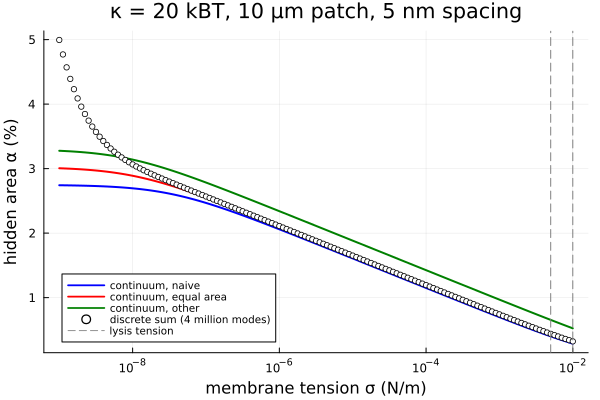

In [33]:

p2 = plot(xscale=:log10, xlabel="membrane tension σ (N/m)",
          ylabel="hidden area α (%)", legend=:bottomleft,  
          title="κ = 20 kBT, 10 μm patch, 5 nm spacing", 
          legendfontsize=7)  

cols = [:blue,:red,:green]

sig_lys = (5e-3, 10e-3)

for ((name, qlo, qhi), c) in zip(choices, cols)
    plot!(p2, sigmas, 100 .* alpha_cont.(sigmas, kappa, qlo, qhi), color=c,
          linewidth=2, label="continuum, $name") 
end 

scatter!(p2, sigmas, 100 .* alpha_d, markershape=:circle, markersize=3,
         markercolor=:white, markerstrokecolor=:black,  
         label="discrete sum (4 million modes)")  

vline!(p2, [sig_lys[1], sig_lys[2]], color=:gray, linestyle=:dash,
       label="lysis tension")  

savefig(p2, "fig2_discrete_vs_continuum.png")

p2

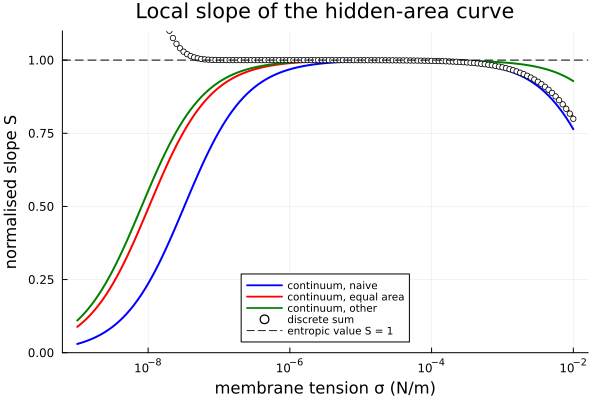

In [34]:

p3 = plot(xscale=:log10, xlabel="membrane tension σ (N/m)",
          ylabel="normalised slope S", ylims=(0, 1.1),  
          title="Local slope of the hidden-area curve", 
          legend=:bottom, legendfontsize=7) 

for ((name, qlo, qhi), c) in zip(choices, cols)
    plot!(p3, sigmas, slope_cont.(sigmas, kappa, qlo, qhi), color=c, linewidth=2,
          label="continuum, $name") 
end 

scatter!(p3, sigmas, slope_d, markershape=:circle, markersize=3, markercolor=:white,
         markerstrokecolor=:black, label="discrete sum") 

hline!(p3, [1.0], color=:black, linestyle=:dash, label="entropic value S = 1")

savefig(p3, "fig3_slope.png")

p3

In [35]:

@printf("discrete S for 1e-6 <= sigma <= 1e-4: %.4f to %.4f\n",
        minimum(slope_d[mid]), maximum(slope_d[mid])) 

shift_theory = kT / (4 * pi * kappa) * log(2)

alpha_other = alpha_cont(1e-5, kappa, pi / L, 2 * pi / a)

alpha_naive = alpha_cont(1e-5, kappa, qmin, qmax)

@printf("shift: predicted %.3f %%, from Eq. (4) %.3f %%\n",
        100 * shift_theory, 100 * (alpha_other - alpha_naive))

discrete S for 1e-6 <= sigma <= 1e-4: 0.9975 to 1.0000
shift: predicted 0.276 %, from Eq. (4) 0.276 %


In [15]:

iA = argmin(abs.(sigmas .- 1e-6))
iB = argmin(abs.(sigmas .- 1e-4))

d_alpha = alpha_d[iA] - alpha_d[iB]

kappa_2pt = kT / (8 * pi) * log(sigmas[iB] / sigmas[iA]) / d_alpha

@printf("alpha(1e-6) = %.3f %%, alpha(1e-4) = %.3f %%\n",
        100 * alpha_d[iA], 100 * alpha_d[iB])  

@printf("Delta alpha = %.3f %%, kappa from two tensions = %.2f kT\n",
        100 * d_alpha, kappa_2pt / kT) 

alpha(1e-6) = 2.110 %, alpha(1e-4) = 1.194 %
Delta alpha = 0.916 %, kappa from two tensions = 20.01 kT
